In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "data/processed/online_retail_cleaned.csv"
)

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("Dataset loaded!")
print(df.shape)

C:\Users\pranj\AppData\Local\Temp\ipykernel_10848\2526423082.py:4: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


Dataset loaded!
(524878, 9)


In [2]:
rfm_df = df.dropna(subset=["CustomerID"]).copy()

print("RFM dataset shape:", rfm_df.shape)
print("Unique customers:", rfm_df["CustomerID"].nunique())

RFM dataset shape: (392692, 9)
Unique customers: 4338


In [3]:
df = pd.read_csv(
    "data/processed/online_retail_cleaned.csv",
    low_memory=False
)

In [4]:
df = pd.read_csv(
    "data/processed/online_retail_cleaned.csv",
    dtype={"InvoiceNo": "string"},
    low_memory=False
)

In [5]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [6]:
print(df.dtypes)

InvoiceNo              string
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
TotalSales            float64
dtype: object


In [7]:
rfm_df = df.dropna(subset=["CustomerID"]).copy()

print("RFM dataset shape:", rfm_df.shape)
print("Unique customers:", rfm_df["CustomerID"].nunique())

RFM dataset shape: (392692, 9)
Unique customers: 4338


In [8]:
# Reference date for Recency calculation
analysis_date = rfm_df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics
rfm = rfm_df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (analysis_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalSales": "sum"
})

# Rename columns
rfm.columns = ["Recency", "Frequency", "Monetary"]

print("RFM table created successfully!")
print("Shape:", rfm.shape)

rfm.head()

RFM table created successfully!
Shape: (4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [9]:
# RFM Scoring

# Recency:
# Lower recency is better, so scores are reversed
rfm["R"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1]
)

# Frequency:
# Higher frequency is better
rfm["F"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

# Monetary:
# Higher spending is better
rfm["M"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

# Convert scores to integers
rfm["R"] = rfm["R"].astype(int)
rfm["F"] = rfm["F"].astype(int)
rfm["M"] = rfm["M"].astype(int)

# Calculate total RFM score
rfm["RFM_Score"] = (
    rfm["R"] +
    rfm["F"] +
    rfm["M"]
)

print("RFM scoring completed!")
rfm.head(10)

RFM scoring completed!


,Recency,Frequency,Monetary,R,F,M,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,5,7
12347.0,2,7,4310.00,5,5,5,15
12348.0,75,4,1797.24,2,4,4,10
12349.0,19,1,1757.55,4,1,4,9
12350.0,310,1,334.40,1,1,2,4
12352.0,36,8,2506.04,3,5,5,13
12353.0,204,1,89.00,1,1,1,3
12354.0,232,1,1079.40,1,1,4,6
12355.0,214,1,459.40,1,1,2,4


In [10]:
def customer_segment(row):

    if row["RFM_Score"] >= 13:
        return "Champions"

    elif row["RFM_Score"] >= 10:
        return "Loyal Customers"

    elif row["RFM_Score"] >= 7:
        return "Potential Loyalists"

    elif row["RFM_Score"] >= 5:
        return "At Risk"

    else:
        return "Lost Customers"


rfm["Segment"] = rfm.apply(customer_segment, axis=1)

print("Customer segmentation completed!")

rfm[["Recency", "Frequency", "Monetary",
     "RFM_Score", "Segment"]].head(10)

Customer segmentation completed!


,Recency,Frequency,Monetary,RFM_Score,Segment
CustomerID,,,,,
12346.0,326,1,77183.60,7,Potential Loyalists
12347.0,2,7,4310.00,15,Champions
12348.0,75,4,1797.24,10,Loyal Customers
12349.0,19,1,1757.55,9,Potential Loyalists
12350.0,310,1,334.40,4,Lost Customers
12352.0,36,8,2506.04,13,Champions
12353.0,204,1,89.00,3,Lost Customers
12354.0,232,1,1079.40,6,At Risk
12355.0,214,1,459.40,4,Lost Customers


In [11]:
segment_counts = rfm["Segment"].value_counts()

print(segment_counts)

Segment
Potential Loyalists    1088
Loyal Customers        1010
Champions               933
At Risk                 763
Lost Customers          544
Name: count, dtype: int64


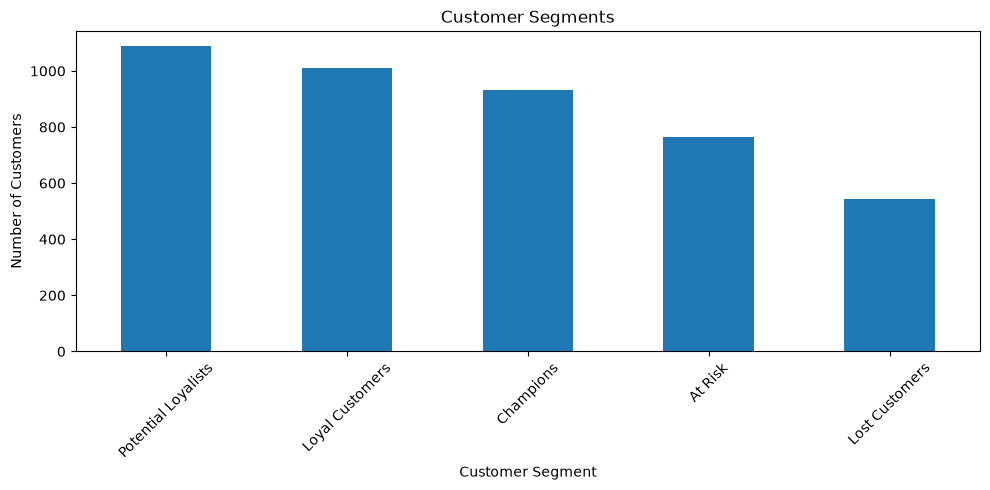

In [12]:
import matplotlib.pyplot as plt

segment_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
rfm.to_csv(
    "data/processed/customer_rfm.csv",
    index=True
)

print("RFM dataset saved successfully!")

RFM dataset saved successfully!
